In [1]:
import os
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

In [26]:
DATA_PATH = '../mitbih_database/'

FS = 360
BEFORE = 80
AFTER = 100
TOLERANCE = 50

In [27]:
def load_annotations(path):
    return pd.read_csv(path, sep='\t')

def detect_r_peaks(signal):
    peaks, _ = find_peaks(
        signal,
        distance=int(0.45 * FS),
        prominence=0.3
    )

    return peaks

def find_annotation(peak, annotations, tolerance=50):
    annotation_samples = annotations['Sample #'].to_numpy()

    if len(annotation_samples) == 0:
        return None, None

    distances = np.abs(annotation_samples - peak)
    idx = np.argmin(distances)

    if distances[idx] <= tolerance:
        return (
            annotations.iloc[idx]['Type'],
            annotation_samples[idx]
        )

    return None, None

In [28]:
all_beats = []

record_files = [
    f for f in os.listdir(DATA_PATH)
    if f.endswith('_record.csv')
]

for record_file in record_files:
    record_id = record_file.replace('_record.csv', '')

    record_path = os.path.join(
        DATA_PATH,
        record_file
    )

    annotation_path = os.path.join(
        DATA_PATH,
        f'{record_id}_annotation.txt'
    )

    print(f'Processing record {record_id}...')
    
    ecg = pd.read_csv(record_path)
    
    if 'MLII' not in ecg.columns:
        print(f'{record_id}: brak MLII - pomijam')
        continue
    
    signal = ecg['MLII'].to_numpy()
    
    if os.path.exists(annotation_path):
        annotations = load_annotations(annotation_path)
    else:
        annotations = pd.DataFrame(
            columns=['Sample #', 'Type']
        )
        
    peaks = detect_r_peaks(signal)
    
    for peak in peaks:
        start = peak - BEFORE
        end = peak + AFTER
        
        if start < 0 or end > len(signal):
            continue
        
        beat = signal[start:end]
        
        beat_type, annotation_sample = find_annotation(
            peak,
            annotations,
            tolerance=TOLERANCE
        )
        
        row = {
            'record_id': record_id,
            'r_peak': peak,
            'annotation_sample': annotation_sample,
            'type': beat_type,
            'dist_from_annotation': abs(annotation_sample - peak) if annotation_sample is not None else np.nan
        }
        
        for i, value in enumerate(beat):
            row[f'x_{i}'] = value
        
        all_beats.append(row)

Processing record 100...
Processing record 101...
Processing record 102...
102: brak MLII - pomijam
Processing record 103...
Processing record 104...
104: brak MLII - pomijam
Processing record 105...
Processing record 106...
Processing record 107...
Processing record 108...
Processing record 109...
Processing record 111...
Processing record 112...
Processing record 113...
Processing record 114...
Processing record 115...
Processing record 116...
Processing record 117...
Processing record 118...
Processing record 119...
Processing record 121...
Processing record 122...
Processing record 123...
Processing record 124...
Processing record 200...
Processing record 201...
Processing record 202...
Processing record 203...
Processing record 205...
Processing record 207...
Processing record 208...
Processing record 209...
Processing record 210...
Processing record 212...
Processing record 213...
Processing record 214...
Processing record 215...
Processing record 217...
Processing record 219...


In [29]:
beats_df = pd.DataFrame(all_beats)

In [30]:
beats_df.head()

,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_170,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179
0,100,370,370.0,N,0.0,-0.280,-0.295,-0.305,-0.315,-0.305,...,-0.450,-0.455,-0.450,-0.435,-0.445,-0.450,-0.455,-0.470,-0.460,-0.455
1,100,663,662.0,N,1.0,-0.335,-0.330,-0.335,-0.345,-0.345,...,-0.410,-0.435,-0.430,-0.435,-0.420,-0.420,-0.420,-0.420,-0.425,-0.425
2,100,947,946.0,N,1.0,-0.345,-0.345,-0.345,-0.340,-0.310,...,-0.375,-0.375,-0.365,-0.370,-0.385,-0.395,-0.385,-0.385,-0.370,-0.365
3,100,1231,1231.0,N,0.0,-0.330,-0.320,-0.290,-0.290,-0.300,...,-0.445,-0.470,-0.455,-0.460,-0.440,-0.435,-0.425,-0.430,-0.445,-0.450
4,100,1515,1515.0,N,0.0,-0.320,-0.310,-0.305,-0.305,-0.275,...,-0.430,-0.445,-0.440,-0.435,-0.430,-0.430,-0.450,-0.445,-0.445,-0.435


In [31]:
beats_df.shape

(103665, 185)

In [32]:
beats_df['type'].value_counts(dropna=False)

type
N      73308
R       7257
L       6521
NaN     4725
V       4205
/       3613
A       2215
F        781
f        259
j        228
!        190
E        102
a         98
J         73
|         24
~         18
+         16
e         16
Q          9
x          3
S          2
]          1
"          1
Name: count, dtype: int64

### Typy uderzeń EKG wykorzystane w eksperymencie

| Symbol | Typ uderzenia | Klasa w modelu |
|:------:|---------------|:--------------:|
| `N` | Normal beat – normalne uderzenie serca | **Normal** |
| `L` | Left bundle branch block beat – uderzenie z blokiem lewej odnogi pęczka Hisa | **Anomaly** |
| `R` | Right bundle branch block beat – uderzenie z blokiem prawej odnogi pęczka Hisa | **Anomaly** |
| `A` | Atrial premature beat – przedwczesne uderzenie przedsionkowe | **Anomaly** |
| `a` | Aberrated atrial premature beat – aberracyjne przedwczesne uderzenie przedsionkowe | **Anomaly** |
| `J` | Nodal (junctional) premature beat – przedwczesne uderzenie węzłowe | **Anomaly** |
| `S` | Supraventricular premature beat – przedwczesne uderzenie nadkomorowe | **Anomaly** |
| `V` | Premature ventricular contraction – przedwczesne pobudzenie komorowe (PVC) | **Anomaly** |
| `E` | Ventricular escape beat – komorowe pobudzenie zastępcze | **Anomaly** |
| `F` | Fusion of ventricular and normal beat – uderzenie fuzyjne komorowe i prawidłowe | **Anomaly** |

In [33]:
normal_types = ['N']
anomaly_types = ['L', 'R', 'A', 'a', 'J', 'S', 'V', 'E', 'F']

valid_types = normal_types + anomaly_types

model_df = beats_df[
    beats_df['type'].isin(valid_types)
].copy()

model_df['anomaly'] = np.where(
    model_df['type'] == 'N',
    0,
    1
)

In [34]:
model_df.head()

,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179,anomaly
0,100,370,370.0,N,0.0,-0.280,-0.295,-0.305,-0.315,-0.305,...,-0.455,-0.450,-0.435,-0.445,-0.450,-0.455,-0.470,-0.460,-0.455,0
1,100,663,662.0,N,1.0,-0.335,-0.330,-0.335,-0.345,-0.345,...,-0.435,-0.430,-0.435,-0.420,-0.420,-0.420,-0.420,-0.425,-0.425,0
2,100,947,946.0,N,1.0,-0.345,-0.345,-0.345,-0.340,-0.310,...,-0.375,-0.365,-0.370,-0.385,-0.395,-0.385,-0.385,-0.370,-0.365,0
3,100,1231,1231.0,N,0.0,-0.330,-0.320,-0.290,-0.290,-0.300,...,-0.470,-0.455,-0.460,-0.440,-0.435,-0.425,-0.430,-0.445,-0.450,0
4,100,1515,1515.0,N,0.0,-0.320,-0.310,-0.305,-0.305,-0.275,...,-0.445,-0.440,-0.435,-0.430,-0.430,-0.450,-0.445,-0.445,-0.435,0


In [35]:
model_df['anomaly'].value_counts()

anomaly
0    73308
1    21254
Name: count, dtype: int64

In [36]:
model_df['type'].value_counts()

type
N    73308
R     7257
L     6521
V     4205
A     2215
F      781
E      102
a       98
J       73
S        2
Name: count, dtype: int64

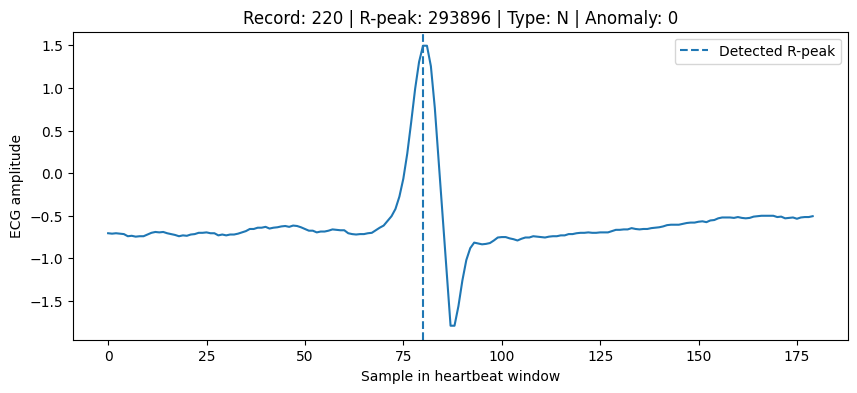

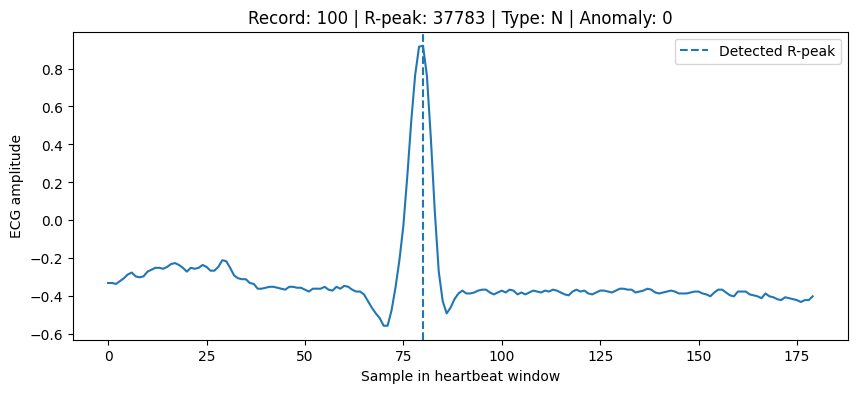

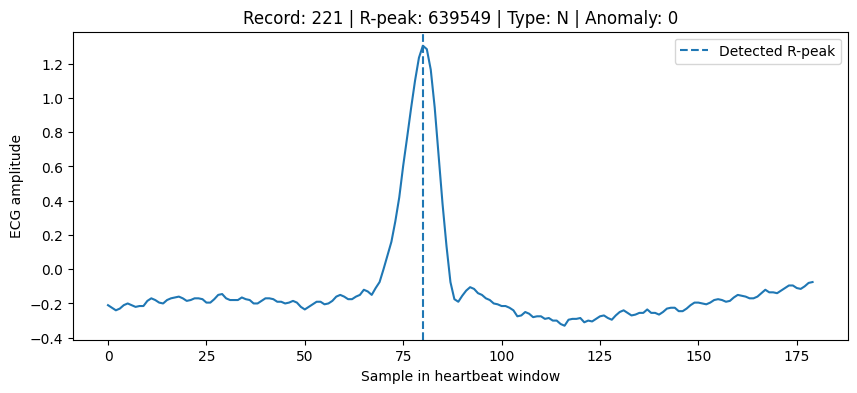

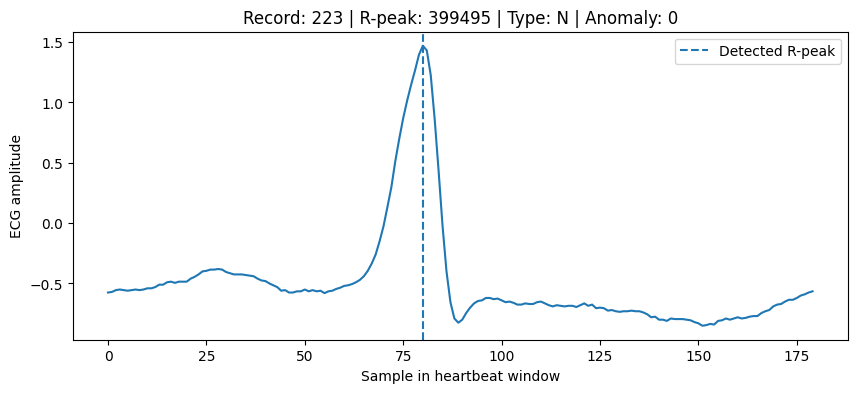

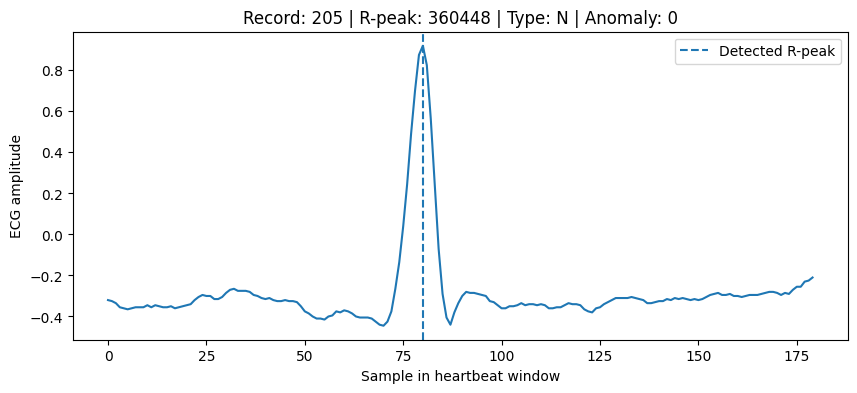

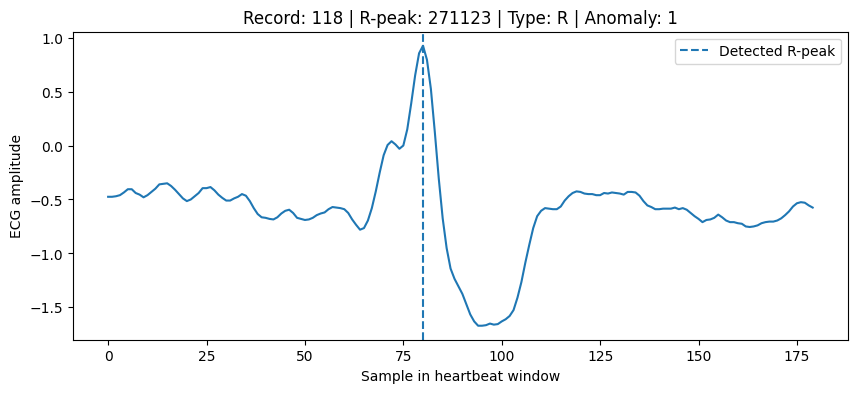

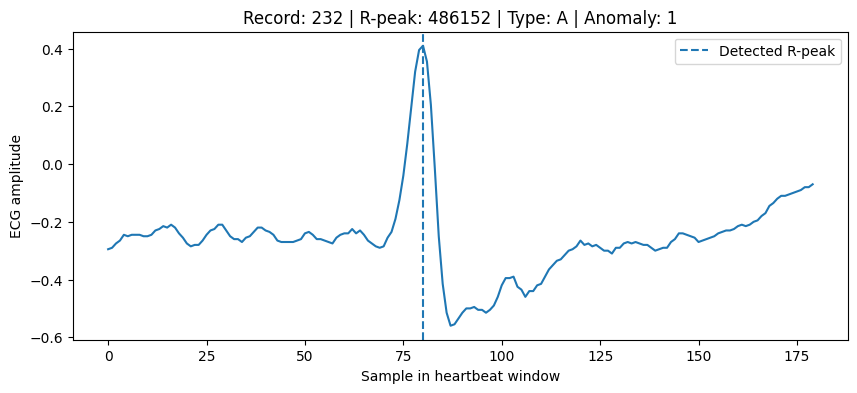

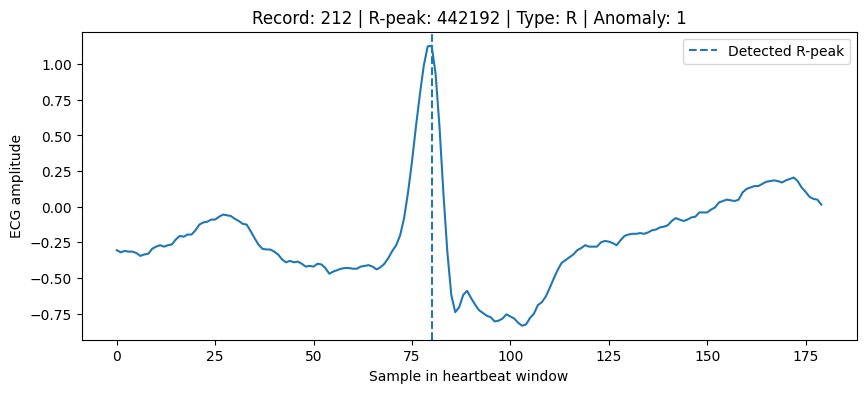

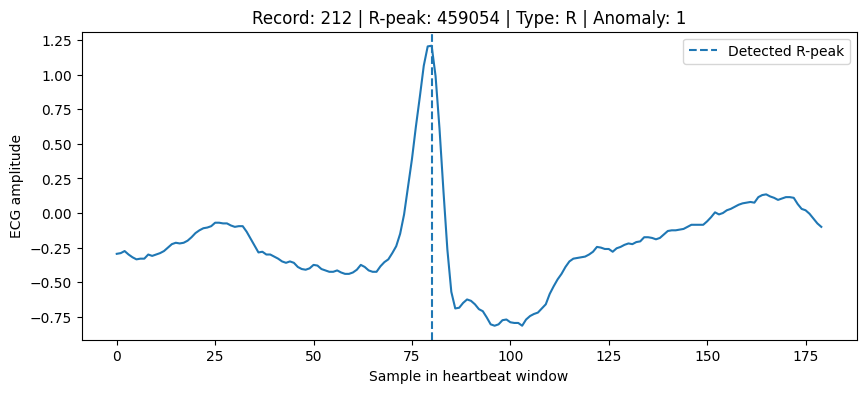

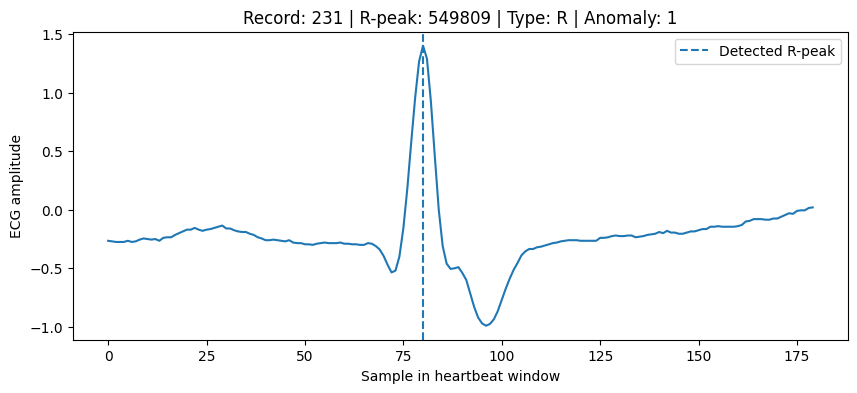

In [39]:
signal_columns = [f'x_{i}' for i in range(180)]

# losujemy np. 6 uderzeń
normal_sample = model_df[
    model_df['anomaly'] == 0
].sample(5, random_state=42)

anomaly_sample = model_df[
    model_df['anomaly'] == 1
].sample(5, random_state=42)

sample_df = pd.concat([
    normal_sample,
    anomaly_sample
])

for idx, row in sample_df.iterrows():

    signal = row[signal_columns].to_numpy(dtype=float)

    plt.figure(figsize=(10, 4))

    plt.plot(
        np.arange(len(signal)),
        signal
    )

    # miejsce, w którym powinien znajdować się R-peak
    plt.axvline(
        80,
        linestyle='--',
        label='Detected R-peak'
    )

    plt.title(
        f"Record: {row['record_id']} | "
        f"R-peak: {row['r_peak']} | "
        f"Type: {row['type']} | "
        f"Anomaly: {row['anomaly']}"
    )

    plt.xlabel('Sample in heartbeat window')
    plt.ylabel('ECG amplitude')

    plt.legend()
    plt.show()

Do modelu OCSVM - całość danych. Do modeli klasyfikacyjnych wykorzystane będą tylko najczęstsze typy anomalii (ze względu na jakość uczenia), tzn. N, R, L, V, A.

In [41]:
output_path = '../src/clean_data.csv'

model_df.to_csv(output_path)

In [43]:
beat_203 = model_df[
    (model_df['record_id'] == 203)
]

beat_203

,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179,anomaly


In [ ]:
signal_columns = [f'x_{i}' for i in range(280)]

signal_203 = beat_203[signal_columns].iloc[0].to_numpy(dtype=float)